First, load the package and instantiate the dependencies.

In [1]:
using Pkg
pkg"activate .; instantiate; precompile" # may take a long time the first time this is run

  Updating registry at `~/.julia/registries/General`
  Updating git-repo `https://github.com/JuliaRegistries/General.git`
Precompiling project...


And load the deps

In [2]:
using CSV, Plots, JSON, BenchmarkTools, Parameters, PerlaTonettiWaugh, DataFrames
gr(fmt = :png)

Plots.GRBackend()

## Stationary Solutions

First, define common objects for the full model

In [3]:
parameters = parameter_defaults(); # model parameters
settings = settings_defaults(run_global = false); # numerical solution settings

To solve for time 0 and ``T`` stationary solutions, simply:

In [4]:
@unpack stationary_T, stationary_0, change_welfare, change_trade = compare_steady_states(parameters, settings)

(stationary_0 = (F = getfield(PerlaTonettiWaugh, Symbol("#F#32")){Float64}(5.0018), r = 0.04824173792862277, ν = 1.513780919242615, a = 10.907680500455738, b = 0.6025760077344995, S = 0.09895175793643815, L_tilde = 0.23057611231055716, L_tilde_x = 0.02091383437396847, L_tilde_E = 0.11454121753418697, L_tilde_a = 0.09512106040240172, z_bar = 1.3429121914497772, w = 0.9196144163671052, x = 1.0, π_min = 0.18664761003589175, π_rat = 1.8110075391436142, g = 0.006741737928622765, z_hat = 1.977552458989574, Ω = 0.9612872210264612, v_tilde = [4.97127, 4.96403, 4.95681, 4.9496, 4.94241, 4.93524, 4.92809, 4.92096, 4.91384, 4.90674  …  3.66752, 3.66783, 3.66804, 3.66812, 3.66781, 3.66641, 3.66156, 3.64577, 3.5951, 3.43314], y = 1.033268719170837, c = 1.033268719170837, λ_ii = 0.8956061037785191, U_bar = 16.1068138146837), stationary_T = (F = getfield(PerlaTonettiWaugh, Symbol("#F#32")){Float64}(5.0018), r = 0.05007041691474591, ν = 1.4242282908627217, a = 10.454638278065985, b = 0.525820985760573

We can inspect each:

In [5]:
foreach(println, pairs(stationary_0))

Pair{Symbol,Any}(:F, #F#32{Float64}(5.0018))
Pair{Symbol,Any}(:r, 0.0482417)
Pair{Symbol,Any}(:ν, 1.51378)
Pair{Symbol,Any}(:a, 10.9077)
Pair{Symbol,Any}(:b, 0.602576)
Pair{Symbol,Any}(:S, 0.0989518)
Pair{Symbol,Any}(:L_tilde, 0.230576)
Pair{Symbol,Any}(:L_tilde_x, 0.0209138)
Pair{Symbol,Any}(:L_tilde_E, 0.114541)
Pair{Symbol,Any}(:L_tilde_a, 0.0951211)
Pair{Symbol,Any}(:z_bar, 1.34291)
Pair{Symbol,Any}(:w, 0.919614)
Pair{Symbol,Any}(:x, 1.0)
Pair{Symbol,Any}(:π_min, 0.186648)
Pair{Symbol,Any}(:π_rat, 1.81101)
Pair{Symbol,Any}(:g, 0.00674174)
Pair{Symbol,Any}(:z_hat, 1.97755)
Pair{Symbol,Any}(:Ω, 0.961287)
Pair{Symbol,Any}(:v_tilde, [4.97127, 4.96403, 4.95681, 4.9496, 4.94241, 4.93524, 4.92809, 4.92096, 4.91384, 4.90674, 4.89966, 4.8926, 4.88555, 4.87853, 4.87151, 4.86452, 4.85755, 4.85059, 4.84365, 4.83672, 4.82981, 4.82292, 4.81605, 4.8092, 4.80236, 4.79554, 4.78873, 4.78194, 4.77517, 4.76842, 4.76168, 4.75496, 4.74826, 4.74157, 4.7349, 4.72825, 4.72161, 4.71499, 4.70838, 4.7018, 4.6

And

In [6]:
foreach(println, pairs(stationary_T))

Pair{Symbol,Any}(:F, #F#32{Float64}(5.0018))
Pair{Symbol,Any}(:r, 0.0500704)
Pair{Symbol,Any}(:ν, 1.42423)
Pair{Symbol,Any}(:a, 10.4546)
Pair{Symbol,Any}(:b, 0.525821)
Pair{Symbol,Any}(:S, 0.108098)
Pair{Symbol,Any}(:L_tilde, 0.235066)
Pair{Symbol,Any}(:L_tilde_x, 0.0284007)
Pair{Symbol,Any}(:L_tilde_E, 0.10836)
Pair{Symbol,Any}(:L_tilde_a, 0.0983055)
Pair{Symbol,Any}(:z_bar, 1.33558)
Pair{Symbol,Any}(:w, 0.914597)
Pair{Symbol,Any}(:x, 1.0)
Pair{Symbol,Any}(:π_min, 0.187777)
Pair{Symbol,Any}(:π_rat, 1.82894)
Pair{Symbol,Any}(:g, 0.00857042)
Pair{Symbol,Any}(:z_hat, 1.83968)
Pair{Symbol,Any}(:Ω, 0.909407)
Pair{Symbol,Any}(:v_tilde, [4.97162, 4.96438, 4.95716, 4.94995, 4.94276, 4.93559, 4.92843, 4.9213, 4.91418, 4.90707, 4.89999, 4.89292, 4.88587, 4.87883, 4.87182, 4.86482, 4.85783, 4.85087, 4.84392, 4.83698, 4.83007, 4.82317, 4.81629, 4.80942, 4.80257, 4.79574, 4.78892, 4.78212, 4.77534, 4.76858, 4.76183, 4.75509, 4.74837, 4.74167, 4.73499, 4.72832, 4.72167, 4.71503, 4.70841, 4.70181, 4

And display the other objects:

In [7]:
@show change_welfare;

change_welfare = 7.651741624079533


In [8]:
@show change_trade;

change_trade = 0.03820375527471076


## Autarky

Let's also define and inspect the autarky steady state

In [9]:
# Solve for the autarky case
defaults = parameter_defaults()
params_autarky = merge(defaults, (d_T = 1 + (defaults.d_0-1)*2.5,))

autarky_results = compare_steady_states(params_autarky, settings, verbose = true);
# quantities we need for later analysis
stationary_autarky = autarky_results.stationary_T;
lambda_ss_autarky = autarky_results.change_welfare;

SS to SS welfare gain: -15.52230845259983
Change in Trade: -0.10091223964458085
Growth Rates across SS: 0.24380789629243788 (time T) vs 0.6741737928622765 (time 0)


## Transition Dynamics

The code is

In [10]:
cachename = join(hash((parameters = parameters, settings = merge(settings, (interp = typeof(settings.interp),))))) # uniquely identify the run by parameters + settings
cachepath = joinpath(pwd(), "data", cachename * ".csv")
use_cache = true # change this to false if you don't want to use the cache for a run
write_cache = true # change this to false if you don't want to generate *any* cache files for a run

# reading
if isfile(cachepath) && use_cache
    println("using cache.")
    solved = CSV.read(cachepath);
else
    println("solving without cache.")
    @time solution = solve_transition(parameters, settings);
    solved = prepare_results(solution.solve_dynamics_output, stationary_T, stationary_0) # since these are the steady-states we're using
end

# writing
if write_cache
    mkpath(joinpath(pwd(), "data")) # if this doesn't eist for whatever reason
    CSV.write(cachepath, solved) # write DataFrame
    write(joinpath(pwd(), "data", cachename * ".json"), JSON.json((parameters = parameters, settings = merge(settings, (interp = typeof(settings.interp),))))) # write parameters
else
    # nothing
end

filter!(row -> row.t >= 0, solved) # don't plot pre-shock values

solving without cache.
 47.605997 seconds (135.53 M allocations: 62.534 GiB, 23.22% gc time)


,t,g,z_hat,Ω,E,v_1,entry_residual,L_tilde,λ_ii,S,z_bar,c,π_min,log_M,U,π_rat,L_tilde_a,L_tilde_x,L_tilde_E,w,r
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.0,0.00751782,1.87129,0.963349,0.0170201,4.9444,-0.00607622,0.224376,0.863195,0.102834,1.36724,1.06046,0.180954,0.0,19.8664,2.20653,0.0990646,0.0276278,0.097684,0.936273,0.0475671
2,0.25,0.007541,1.87079,0.962633,0.0170324,4.94549,-0.00498943,0.224429,0.863107,0.10295,1.36684,1.06008,0.181058,0.00188235,19.9585,2.20686,0.0991026,0.0276438,0.0976824,0.935997,0.0475954
3,0.5,0.0075641,1.8703,0.961921,0.0170448,4.94656,-0.00391609,0.224481,0.863019,0.103065,1.36643,1.0597,0.181162,0.00377049,20.0508,2.20718,0.0991404,0.0276597,0.0976811,0.935722,0.0476237
4,0.75,0.00758711,1.86981,0.961212,0.0170572,4.94762,-0.00285627,0.224533,0.862931,0.10318,1.36603,1.05931,0.181265,0.00566439,20.1432,2.20751,0.099178,0.0276755,0.09768,0.935448,0.0476517
5,1.0,0.00761004,1.86932,0.960506,0.0170696,4.94866,-0.00181006,0.224586,0.862844,0.103295,1.36564,1.05893,0.181367,0.00756404,20.2357,2.20783,0.0992153,0.0276912,0.0976792,0.935176,0.0476796
6,1.25,0.00763289,1.86884,0.959804,0.017082,4.94969,-0.000777576,0.224638,0.862757,0.103409,1.36524,1.05856,0.181469,0.00946941,20.3283,2.20815,0.0992525,0.0277068,0.0976786,0.934904,0.0477075
7,1.5,0.00765566,1.86836,0.959106,0.0170944,4.95071,0.000241077,0.22469,0.862671,0.103523,1.36485,1.05818,0.181571,0.0113805,20.4211,2.20848,0.0992895,0.0277224,0.0976783,0.934634,0.0477351
8,1.75,0.00767835,1.86788,0.958411,0.0171067,4.95172,0.00124578,0.224743,0.862585,0.103637,1.36445,1.0578,0.181672,0.0132972,20.5139,2.2088,0.0993264,0.0277379,0.0976782,0.934365,0.0477625
9,2.0,0.00770097,1.8674,0.95772,0.0171191,4.9527,0.00223637,0.224795,0.862499,0.10375,1.36406,1.05743,0.181773,0.0152196,20.6068,2.20911,0.0993631,0.0277534,0.0976784,0.934098,0.0477898


## Welfare

Here's welfare inclusive of the transition path:

In [11]:
lambda_tpath = 100*(consumption_equivalent(solved.U[1], stationary_0.U_bar, parameter_defaults())-1);
@show lambda_tpath;

lambda_tpath = 8.418724813298862


## Plots

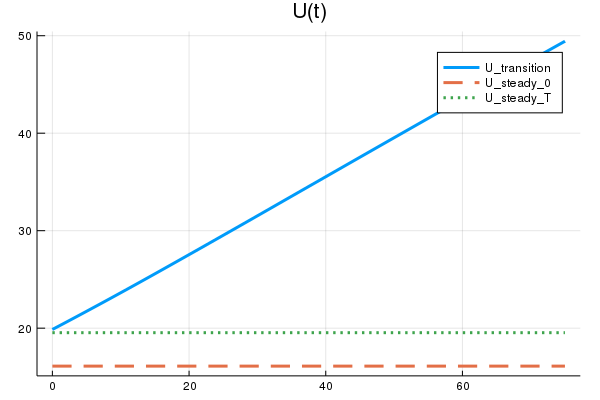

In [12]:
U_steady_0(t) = stationary_0.U_bar
U_steady_T(t) = stationary_T.U_bar

plot(solved.t,
   [solved.U, U_steady_0, U_steady_T],
   label = ["U_transition", "U_steady_0", "U_steady_T"] ,
   title = "U(t)", linestyle = :auto, lw = 3)

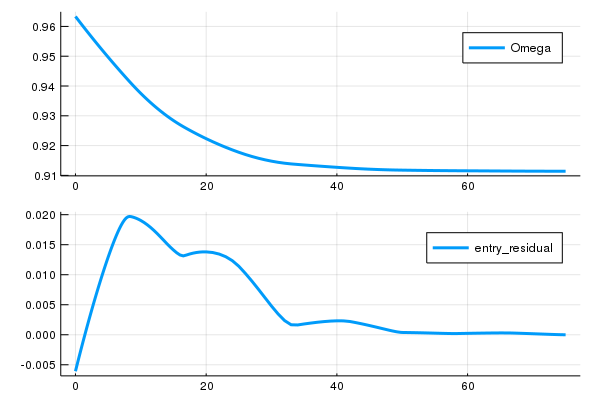

In [13]:
plot_Ω = plot(solved.t, solved.Ω, label = "Omega", lw = 3)
plot_residual = plot(solved.t, solved.entry_residual, label = "entry_residual", lw = 3)
plot(plot_Ω, plot_residual, layout = (2,1))

Here are the static equations

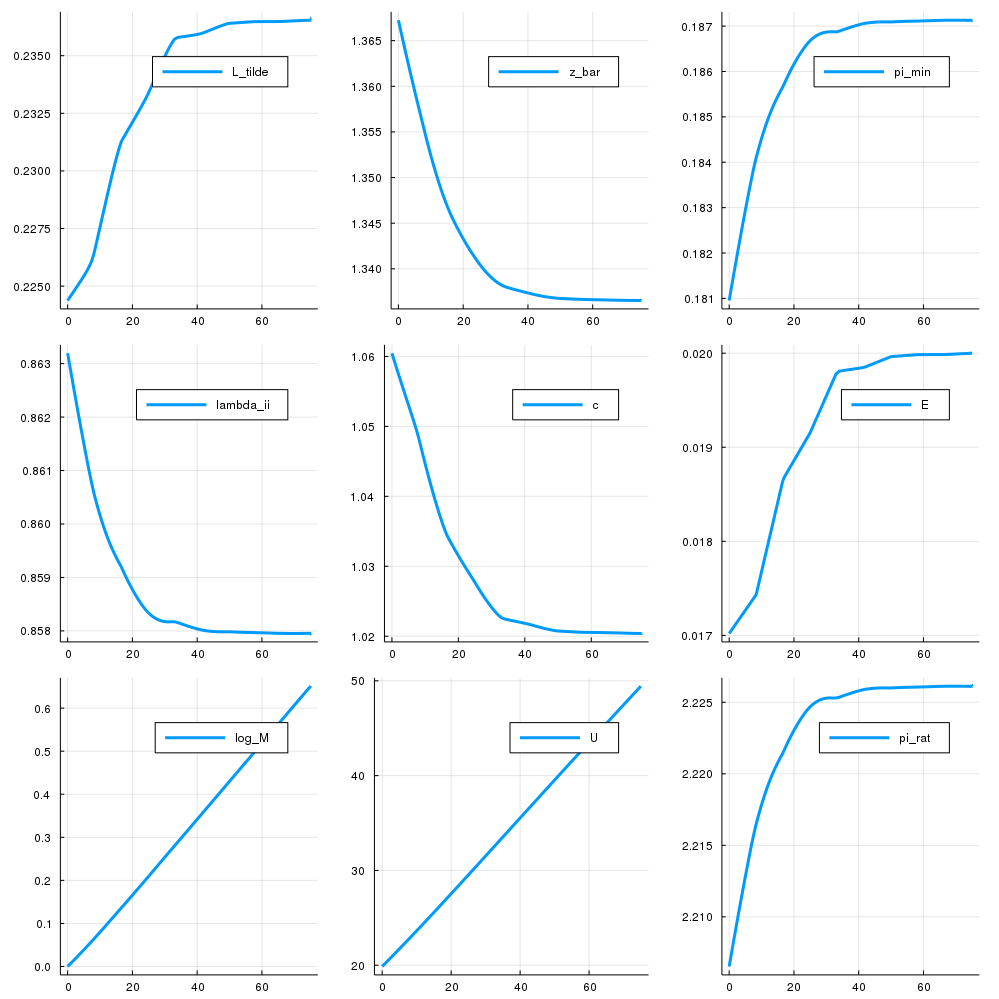

In [14]:
plot1 = plot(solved.t, solved.L_tilde, label = "L_tilde", lw = 3)
plot2 = plot(solved.t, solved.z_bar, label = "z_bar", lw = 3)
plot3 = plot(solved.t, solved.π_min, label = "pi_min", lw = 3)
plot4 = plot(solved.t, solved.λ_ii, label = "lambda_ii", lw = 3)
plot5 = plot(solved.t, solved.c, label = "c", lw = 3)
plot6 = plot(solved.t, solved.E, label = "E", lw = 3)
plot7 = plot(solved.t, solved.log_M, label = "log_M", lw = 3)
plot8 = plot(solved.t, solved.U, label = "U", lw = 3)
plot9 = plot(solved.t, solved.π_rat, label = "pi_rat", lw = 3)
plot(plot1, plot2, plot3, plot4, plot5, plot6, plot7, plot8, plot9, layout=(3,3), size = (1000, 1000))

And a more granular look at welfare

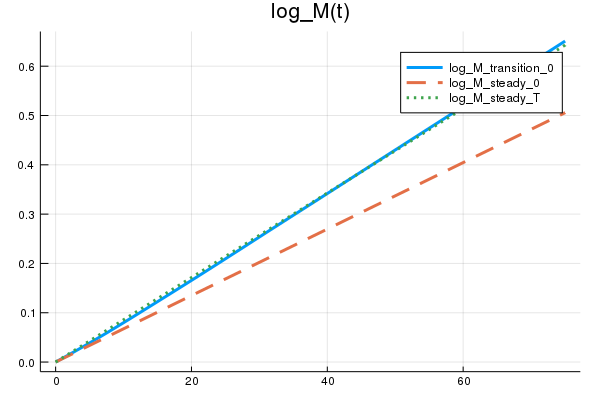

In [15]:
log_M_steady_0(t) = stationary_0.g * t
log_M_steady_T(t) = stationary_T.g * t

plot(solved.t,
    [solved.log_M, log_M_steady_0, log_M_steady_T],
    label = ["log_M_transition_0", "log_M_steady_0", "log_M_steady_T"] ,
    title = "log_M(t)", linestyle = :auto, lw = 3)

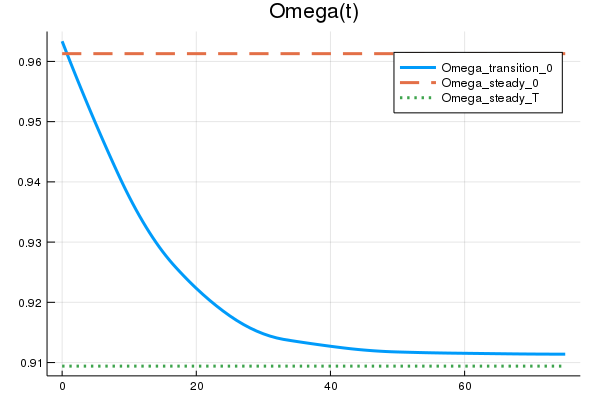

In [16]:
Ω_steady_0(t) = stationary_0.Ω
Ω_steady_T(t) = stationary_T.Ω

plot(solved.t,
    [solved.Ω, Ω_steady_0, Ω_steady_T],
    label = ["Omega_transition_0", "Omega_steady_0", "Omega_steady_T"] ,
    title = "Omega(t)", linestyle = :auto, lw = 3)

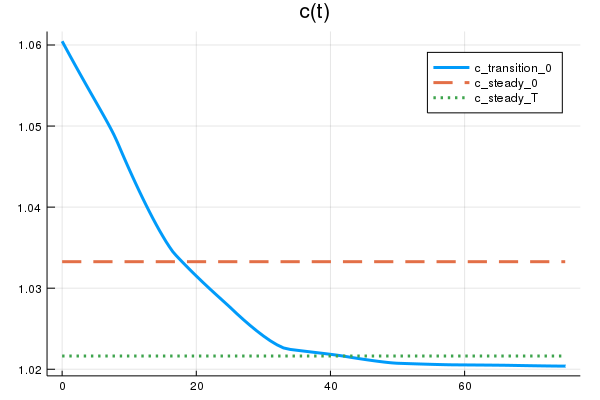

In [17]:
c_steady_0(t) = stationary_0.c
c_steady_T(t) = stationary_T.c

plot(solved.t,
    [solved.c, c_steady_0, c_steady_T],
    label = ["c_transition_0", "c_steady_0", "c_steady_T"] ,
    title = "c(t)", linestyle = :auto, lw = 3)

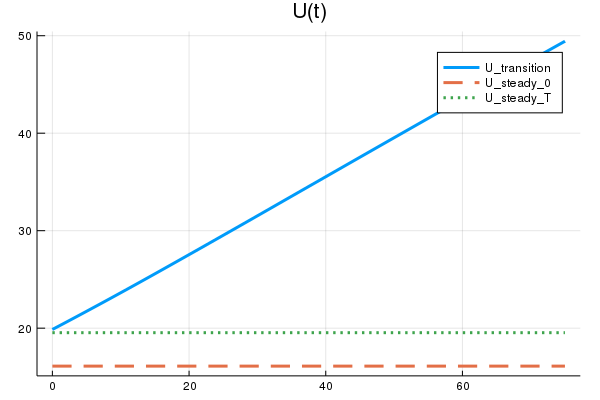

In [18]:
U_steady_0(t) = stationary_0.U_bar
U_steady_T(t) = stationary_T.U_bar

plot(solved.t,
    [solved.U, U_steady_0, U_steady_T],
    label = ["U_transition", "U_steady_0", "U_steady_T"] ,
    title = "U(t)", linestyle = :auto, lw = 3)

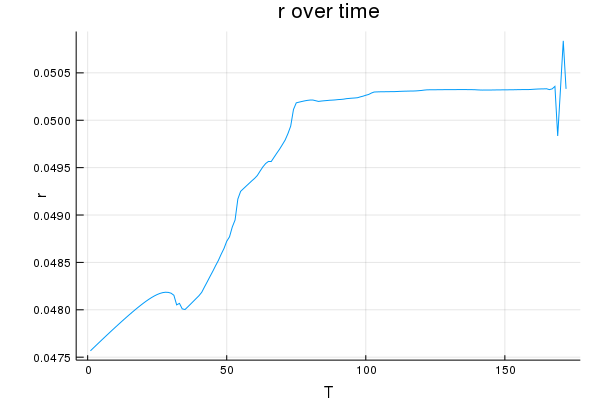

In [19]:
plot(solved.r, legend = false, title = "r over time", xlabel = "T", ylabel = "r")

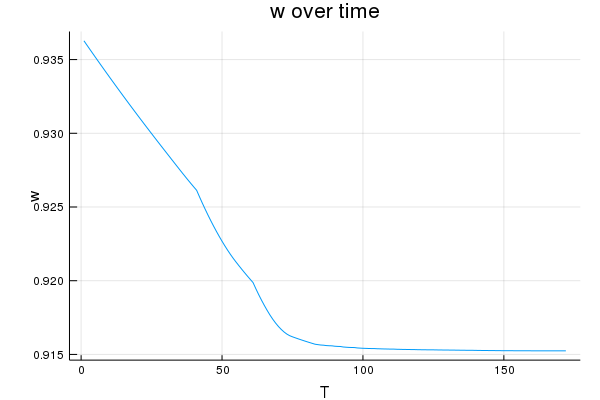

In [20]:
plot(solved.w, legend = false, title = "w over time", xlabel = "T", ylabel = "w")

Here's the labor share breakdown

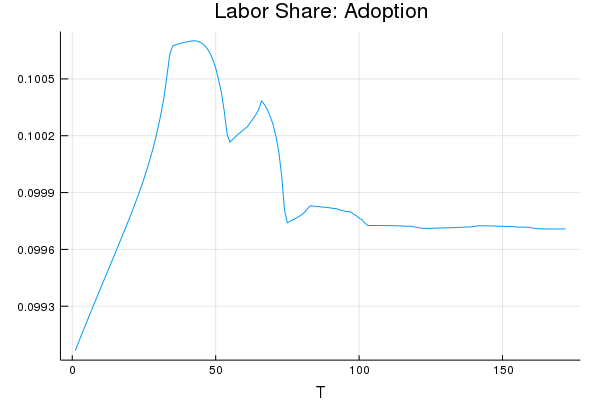

In [21]:
plot(solved.L_tilde_a, legend = false, xlabel = "T", title = "Labor Share: Adoption")

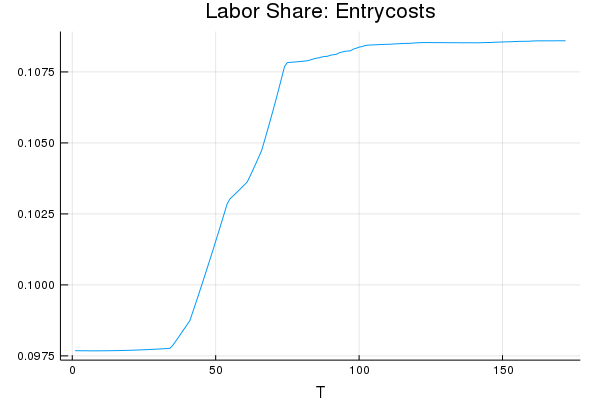

In [22]:
plot(solved.L_tilde_E, legend = false, xlabel = "T", title = "Labor Share: Entrycosts")

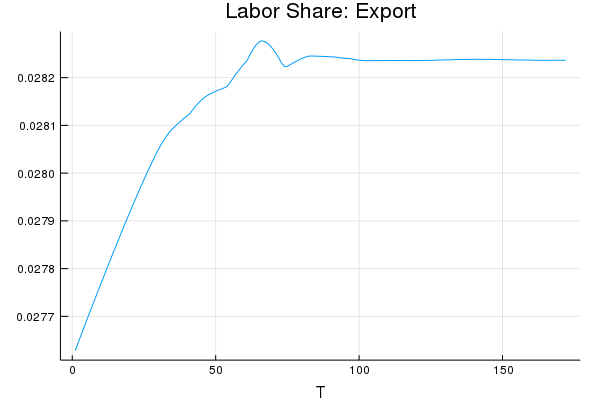

In [23]:
plot(solved.L_tilde_x, legend = false, xlabel = "T", title = "Labor Share: Export")

And the consumption equivalent

In [24]:
T = solved.t[end]
consumption_equivalent(solved.U[1], stationary_0.U_bar, parameter_defaults())

1.0841872481329886

## Writing Data

Save welfare and autarky dataframes.

In [25]:
df_welfare = DataFrame(steady_state = change_welfare, transition_path = lambda_tpath, growth_rate = stationary_T.g, theta = parameter_defaults().θ);
write_cache && CSV.write("data/welfare_results-" * cachename * ".csv", df_welfare)

"data/welfare_results-247621096903001444.csv"

In [26]:
df_autarky = DataFrame(steady_state = lambda_ss_autarky, growth_rate = stationary_autarky.g, theta = parameter_defaults().θ);
write_cache && CSV.write("data/autarky_results-" * cachename * ".csv", df_autarky)

"data/autarky_results-247621096903001444.csv"